# Parte 1 — Análise Exploratória: Churn de Clientes (Telecom)

**Objetivo:** entender o perfil dos clientes que cancelam o serviço (churn) e quais fatores estão mais associados ao cancelamento.

**Fonte:** [Telco Customer Churn — IBM](https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv) — 7.043 clientes, 21 variáveis.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # permite importar src/ a partir de notebooks/

import pandas as pd
import matplotlib.pyplot as plt
from src.dados import carregar_dados, NUMERICAS, CATEGORICAS, ROTULOS
pd.set_option("display.max_columns", 30)

## 1. Dados brutos

In [2]:
bruto = pd.read_csv("../data/telco_churn.csv")
print(bruto.shape)
bruto.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
bruto.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# TotalCharges vem como texto; há linhas em branco
(bruto["TotalCharges"].astype(str).str.strip() == "").sum()

np.int64(11)

In [5]:
bruto[bruto["TotalCharges"].astype(str).str.strip() == ""][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


Os 11 registros com `TotalCharges` vazio são clientes com **0 meses** de contrato, ou seja, ainda não pagaram nada. Por isso o valor correto é 0 (e não excluir as linhas).

## 2. Tratamento
A função `carregar_dados()` (em `src/dados.py`) é usada aqui, no modelo e na dashboard, garantindo o mesmo tratamento em todo o projeto:
- tradução de colunas e categorias para português;
- `TotalCharges` → número (vazios = 0);
- `SeniorCitizen` 0/1 → Não/Sim;
- nova coluna `faixa_permanencia`.

In [6]:
df = carregar_dados()
print(df.shape, "| valores nulos:", df.isna().sum().sum(), "| duplicados:", df["id_cliente"].duplicated().sum())
df.head()

(7043, 22) | valores nulos: 0 | duplicados: 0


,id_cliente,genero,idoso,tem_parceiro,tem_dependentes,meses_contrato,servico_telefone,multiplas_linhas,tipo_internet,seguranca_online,backup_online,protecao_aparelho,suporte_tecnico,streaming_tv,streaming_filmes,tipo_contrato,fatura_digital,forma_pagamento,valor_mensal,valor_total,churn,faixa_permanencia
0,7590-VHVEG,Feminino,Não,Sim,Não,1,Não,Sem telefone,DSL,Não,Sim,Não,Não,Não,Não,Mensal,Sim,Boleto eletrônico,29.85,29.85,Não,0–12 meses
1,5575-GNVDE,Masculino,Não,Não,Não,34,Sim,Não,DSL,Sim,Não,Sim,Não,Não,Não,Anual,Não,Boleto pelo correio,56.95,1889.50,Não,25–48 meses
2,3668-QPYBK,Masculino,Não,Não,Não,2,Sim,Não,DSL,Sim,Sim,Não,Não,Não,Não,Mensal,Sim,Boleto pelo correio,53.85,108.15,Sim,0–12 meses
3,7795-CFOCW,Masculino,Não,Não,Não,45,Não,Sem telefone,DSL,Sim,Não,Sim,Sim,Não,Não,Anual,Não,Débito automático,42.30,1840.75,Não,25–48 meses
4,9237-HQITU,Feminino,Não,Não,Não,2,Sim,Não,Fibra óptica,Não,Não,Não,Não,Não,Não,Mensal,Sim,Boleto eletrônico,70.70,151.65,Sim,0–12 meses


## 3. Variável-alvo

Taxa de churn: 26.5%


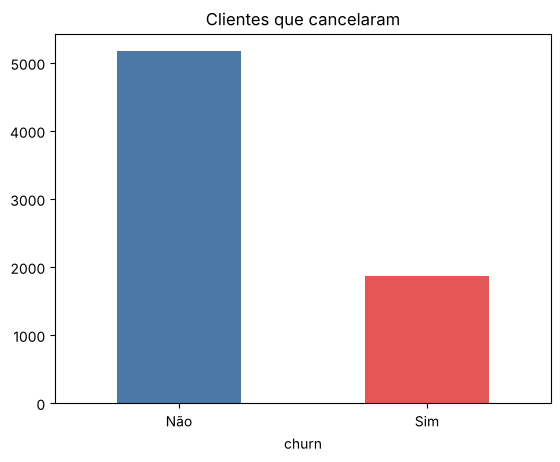

In [7]:
taxa = (df["churn"] == "Sim").mean()
print(f"Taxa de churn: {taxa:.1%}")
df["churn"].value_counts().plot.bar(color=["#4C78A8", "#E45756"], title="Clientes que cancelaram")
plt.xticks(rotation=0); plt.show()

A base é **desbalanceada** (~26,5% de churn). Isso será considerado no modelo (Parte 2) com `class_weight='balanced'` e métricas como recall e F1, não só acurácia.

## 4. Variáveis numéricas

In [8]:
df[NUMERICAS].describe().round(1)

,meses_contrato,valor_mensal,valor_total
count,7043.0,7043.0,7043.0
mean,32.4,64.8,2279.7
std,24.6,30.1,2266.8
min,0.0,18.2,0.0
25%,9.0,35.5,398.6
50%,29.0,70.4,1394.6
75%,55.0,89.8,3786.6
max,72.0,118.8,8684.8


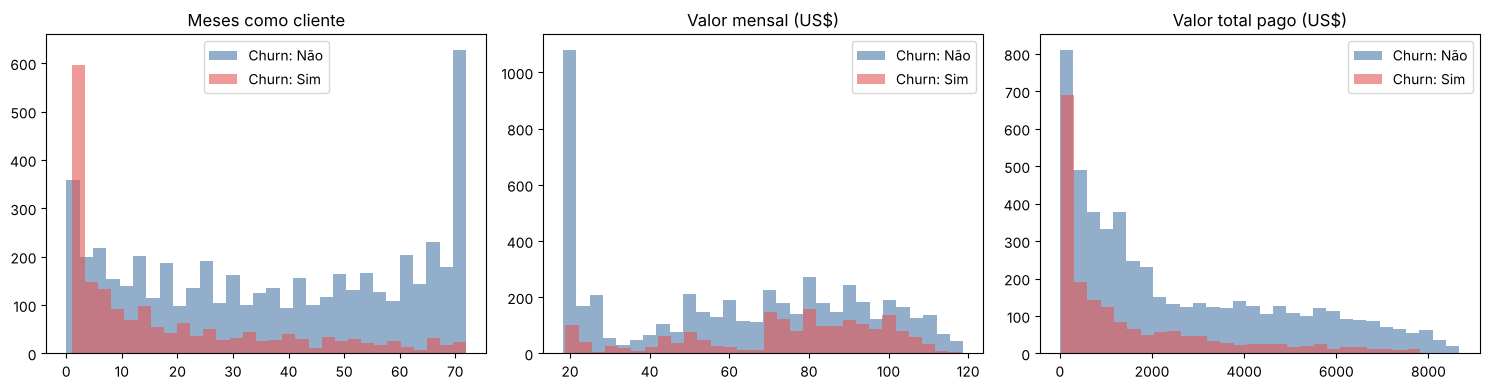

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, NUMERICAS):
    for status, cor in [("Não", "#4C78A8"), ("Sim", "#E45756")]:
        ax.hist(df.loc[df["churn"] == status, col], bins=30, alpha=0.6, color=cor, label=f"Churn: {status}")
    ax.set_title(ROTULOS[col]); ax.legend()
plt.tight_layout(); plt.show()

In [10]:
df.groupby("churn")[NUMERICAS].median().round(1)

,meses_contrato,valor_mensal,valor_total
churn,,,
Não,38.0,64.4,1679.5
Sim,10.0,79.6,703.6


Quem cancela tem **menos tempo de casa** (mediana de 10 meses contra 38) e **paga mais por mês** (US$ 80 contra US$ 64).

## 5. Variáveis categóricas — taxa de churn por categoria

In [11]:
def taxa_por(col):
    return (df.groupby(col)["churn"].apply(lambda s: (s == "Sim").mean())
              .sort_values(ascending=False).rename("taxa_churn"))

for col in ["tipo_contrato", "tipo_internet", "forma_pagamento", "suporte_tecnico", "seguranca_online", "idoso", "faixa_permanencia"]:
    print(f"\n{ROTULOS[col]}"); print((taxa_por(col) * 100).round(1).astype(str) + "%")


Tipo de contrato
tipo_contrato
Mensal    42.7%
Anual     11.3%
Bienal     2.8%
Name: taxa_churn, dtype: str

Tipo de internet
tipo_internet
Fibra óptica    41.9%
DSL             19.0%
Não              7.4%
Name: taxa_churn, dtype: str

Forma de pagamento
forma_pagamento
Boleto eletrônico                 45.3%
Boleto pelo correio               19.1%
Débito automático                 16.7%
Cartão de crédito (automático)    15.2%
Name: taxa_churn, dtype: str

Suporte técnico
suporte_tecnico
Não             41.6%
Sim             15.2%
Sem internet     7.4%
Name: taxa_churn, dtype: str

Segurança online
seguranca_online
Não             41.8%
Sim             14.6%
Sem internet     7.4%
Name: taxa_churn, dtype: str

Idoso (65+)
idoso
Sim    41.7%
Não    23.6%
Name: taxa_churn, dtype: str

Faixa de permanência
faixa_permanencia
0–12 meses     47.4%
13–24 meses    28.7%
25–48 meses    20.4%
49–72 meses     9.5%
Name: taxa_churn, dtype: str


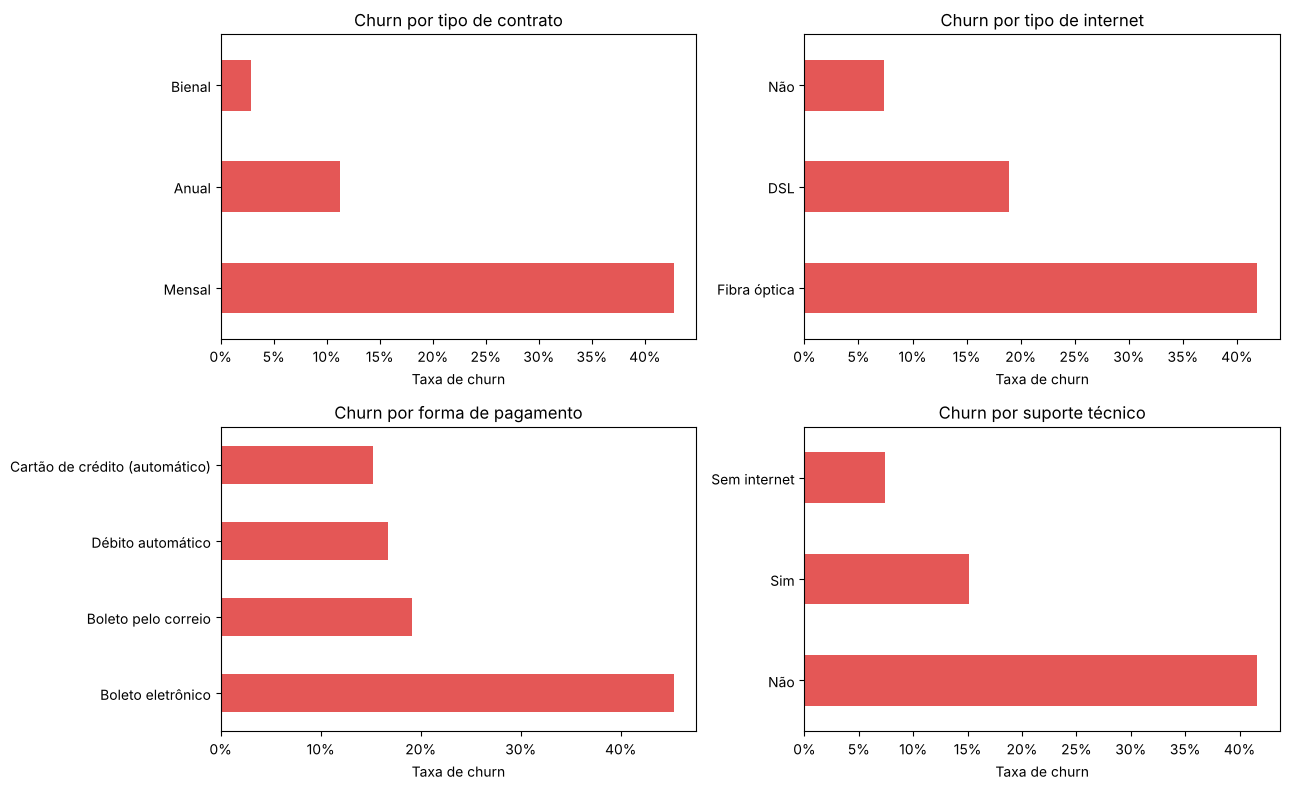

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, ["tipo_contrato", "tipo_internet", "forma_pagamento", "suporte_tecnico"]):
    taxa_por(col).plot.barh(ax=ax, color="#E45756")
    ax.set_title(f"Churn por {ROTULOS[col].lower()}"); ax.set_xlabel("Taxa de churn"); ax.set_ylabel("")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout(); plt.show()

## 6. Correlação

In [13]:
corr = df[NUMERICAS].assign(churn=(df["churn"] == "Sim").astype(int)).corr()
corr.round(2)

,meses_contrato,valor_mensal,valor_total,churn
meses_contrato,1.00,0.25,0.83,-0.35
valor_mensal,0.25,1.00,0.65,0.19
valor_total,0.83,0.65,1.00,-0.20
churn,-0.35,0.19,-0.20,1.00


## 7. Conclusões da análise exploratória

1. **Contrato é o fator mais forte:** contrato mensal tem ~43% de churn, contra ~11% no anual e ~3% no bienal.
2. **Os primeiros 12 meses são críticos:** ~47% dos clientes nessa faixa cancelam; depois de 4 anos, menos de 10%.
3. **Fibra óptica tem churn alto (~42%)**, possivelmente por preço maior ou problemas de qualidade.
4. **Serviços de apoio retêm:** quem não tem suporte técnico ou segurança online cancela cerca de 2,5× mais.
5. **Boleto eletrônico** concentra churn (~45%); pagamentos automáticos ficam em ~15–17%.
6. **Idosos** cancelam mais (~42% contra ~24%).

Essas variáveis devem ter peso relevante no modelo preditivo (Parte 2).